# Unidad 4: Optimización Computacional — Descenso de Gradiente
## Matemáticas para Análisis de Datos — ITEC

**Objetivos de esta notebook:**
- Calcular derivadas parciales del MSE respecto a cada parámetro
- Implementar el algoritmo de Descenso de Gradiente desde cero
- Graficar la curva de pérdida y el camino de convergencia
- Comparar el efecto de distintas tasas de aprendizaje

---
**La regla de actualización central:**
$$\theta \leftarrow \theta - \alpha \cdot \nabla_{\theta} \text{MSE}$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Dataset de casas
x_data = np.array([60.0, 85.0, 120.0, 150.0, 200.0])
y_data = np.array([120000.0, 150000.0, 180000.0, 210000.0, 250000.0])

# Normalizar x para que el gradiente sea más estable
x_mean, x_std = x_data.mean(), x_data.std()
y_mean, y_std = y_data.mean(), y_data.std()
x_norm = (x_data - x_mean) / x_std
y_norm = (y_data - y_mean) / y_std

print("Datos normalizados:")
print("x_norm:", x_norm.round(3))
print("y_norm:", y_norm.round(3))

Datos normalizados:
x_norm: [-1.282 -0.773 -0.061  0.549  1.567]
y_norm: [-1.367 -0.706 -0.044  0.618  1.5  ]


## 1. Derivadas Parciales del MSE

Para el modelo `ŷ = m*x + b`, el MSE es:
$$MSE(m,b) = \frac{1}{n}\sum_i(m \cdot x_i + b - y_i)^2$$

Las derivadas parciales son:
$$\frac{\partial MSE}{\partial m} = \frac{2}{n}\sum_i x_i(m \cdot x_i + b - y_i)$$
$$\frac{\partial MSE}{\partial b} = \frac{2}{n}\sum_i (m \cdot x_i + b - y_i)$$

In [3]:
def mse(m, b, x, y):
    errores = m * x + b - y
    return np.mean(errores**2)

def gradiente(m, b, x, y):
    n = len(x)
    errores = m * x + b - y          # vector de errores
    grad_m = (2 / n) * np.sum(x * errores)   # derivada parcial respecto a m
    grad_b = (2 / n) * np.sum(errores)        # derivada parcial respecto a b
    return grad_m, grad_b

# Verificar en un punto específico
m_test, b_test = 1.0, 0.0
gm, gb = gradiente(m_test, b_test, x_norm, y_norm)
print(f"En m={m_test}, b={b_test}:")
print(f"  ∂MSE/∂m = {gm:.4f}")
print(f"  ∂MSE/∂b = {gb:.4f}")
print(f"  Gradiente apunta a: [{gm:.4f}, {gb:.4f}]")
print(f"  Debemos movernos en dirección contraria para minimizar")

En m=1.0, b=0.0:
  ∂MSE/∂m = 0.0043
  ∂MSE/∂b = -0.0000
  Gradiente apunta a: [0.0043, -0.0000]
  Debemos movernos en dirección contraria para minimizar


## 2. Implementación del Descenso de Gradiente

In [20]:
def descenso_gradiente(x, y, learning_rate=0.1, n_iter=100):
    m, b = 0.0, 0.0  # inicializar en cero
    historial_mse = []
    historial_params = []
    
    for i in range(n_iter):
        costo = mse(m, b, x, y)
        historial_mse.append(costo)
        historial_params.append((m, b))
        
        gm, gb = gradiente(m, b, x, y)
        
        # Actualización: θ ← θ - α * ∇θ
        m = m - learning_rate * gm
        b = b - learning_rate * gb
    
    return m, b, historial_mse, historial_params

m_final, b_final, historial, params_hist = descenso_gradiente(
    x_norm, y_norm, learning_rate=0.1, n_iter=200
)

print(f"Parámetros encontrados (espacio normalizado):")
print(f"  m = {m_final:.6f}")
print(f"  b = {b_final:.6f}")
print(f"  MSE final: {historial[-1]:.8f}")

Parámetros encontrados (espacio normalizado):
  m = 0.997872
  b = 0.000000
  MSE final: 0.00425181


## 3. Curva de Aprendizaje (Loss Curve)

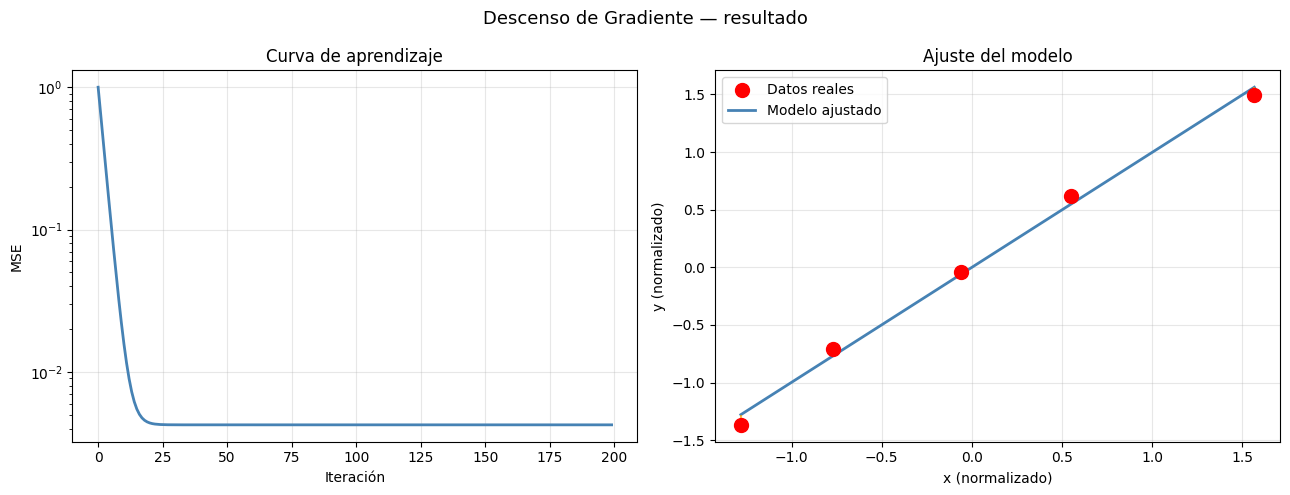

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Curva de pérdida
axes[0].plot(historial, color='steelblue', linewidth=2)
axes[0].set_xlabel('Iteración')
axes[0].set_ylabel('MSE')
axes[0].set_title('Curva de aprendizaje')
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')

# Datos vs. modelo ajustado
x_linea = np.linspace(x_norm.min(), x_norm.max(), 100)
y_linea = m_final * x_linea + b_final

axes[1].scatter(x_norm, y_norm, color='red', s=100, zorder=5, label='Datos reales')
axes[1].plot(x_linea, y_linea, color='steelblue', linewidth=2, label='Modelo ajustado')
for xi, yi in zip(x_norm, y_norm):
    y_pred_i = m_final * xi + b_final
    axes[1].vlines(xi, min(yi, y_pred_i), max(yi, y_pred_i), color='orange', alpha=0.7)
axes[1].set_xlabel('x (normalizado)')
axes[1].set_ylabel('y (normalizado)')
axes[1].set_title('Ajuste del modelo')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Descenso de Gradiente — resultado', fontsize=13)
plt.tight_layout()
plt.show()

## 4. Camino del Gradiente sobre la Superficie de Costo

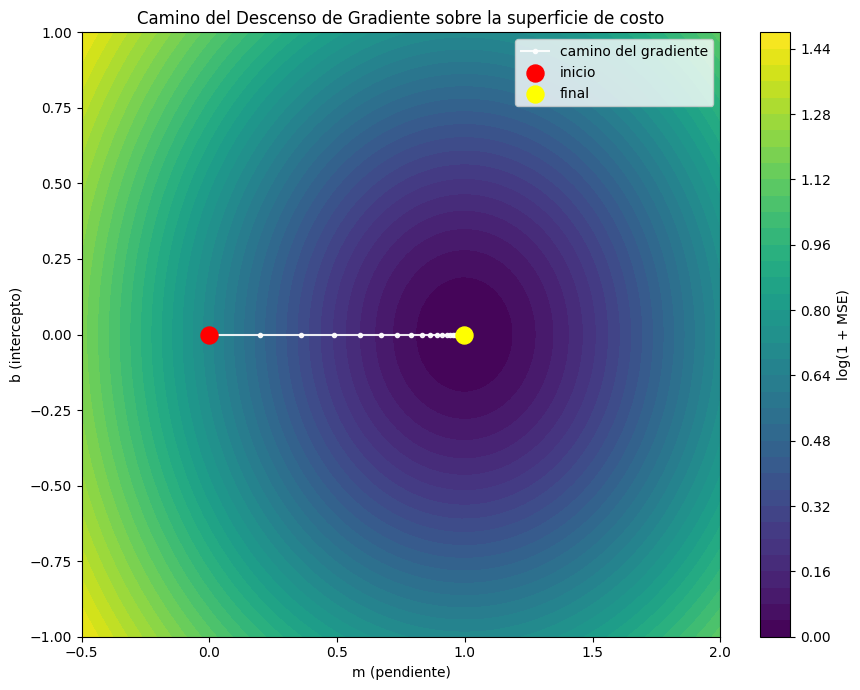

In [6]:
# Superficie de costo
m_range = np.linspace(-0.5, 2.0, 80)
b_range = np.linspace(-1.0, 1.0, 80)
M, B = np.meshgrid(m_range, b_range)
MSE_grid = np.array([[mse(m, b, x_norm, y_norm) for m in m_range] for b in b_range])

# Camino del gradiente
m_hist = [p[0] for p in params_hist]
b_hist = [p[1] for p in params_hist]

fig, ax = plt.subplots(figsize=(9, 7))
cp = ax.contourf(M, B, np.log1p(MSE_grid), levels=40, cmap='viridis')
plt.colorbar(cp, ax=ax, label='log(1 + MSE)')
ax.plot(m_hist, b_hist, 'w-o', markersize=3, linewidth=1.5, alpha=0.9, label='camino del gradiente')
ax.scatter([m_hist[0]], [b_hist[0]], color='red', s=150, zorder=6, label='inicio')
ax.scatter([m_hist[-1]], [b_hist[-1]], color='yellow', s=150, zorder=6, label='final')
ax.set_xlabel('m (pendiente)')
ax.set_ylabel('b (intercepto)')
ax.set_title('Camino del Descenso de Gradiente sobre la superficie de costo')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Impacto de la Tasa de Aprendizaje

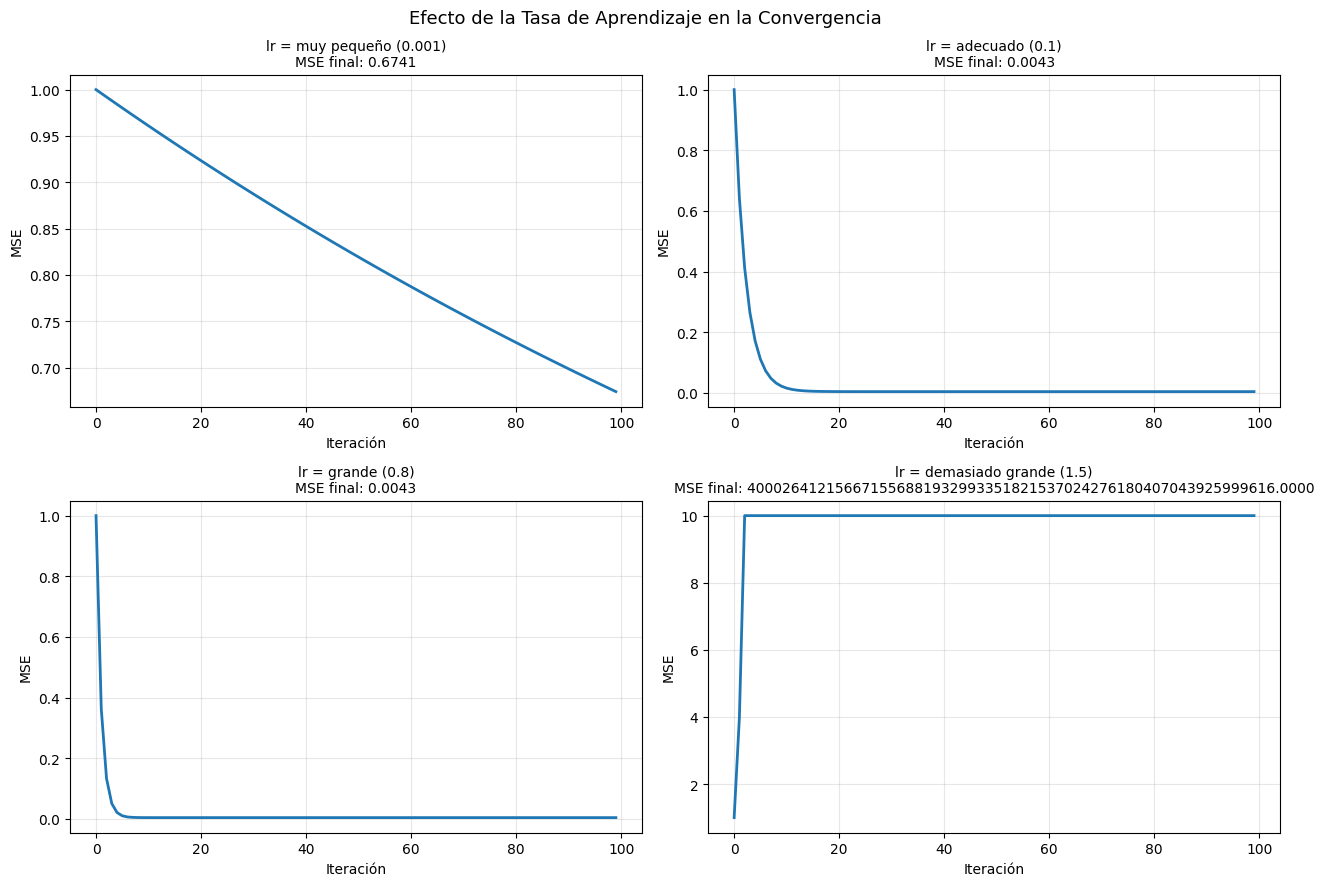

In [7]:
learning_rates = {
    'muy pequeño (0.001)': 0.001,
    'adecuado (0.1)':      0.1,
    'grande (0.8)':        0.8,
    'demasiado grande (1.5)': 1.5
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()

for ax, (nombre, lr) in zip(axes, learning_rates.items()):
    try:
        _, _, hist, _ = descenso_gradiente(x_norm, y_norm, learning_rate=lr, n_iter=100)
        hist_plot = [min(h, 10) for h in hist]  # cap para visualizar divergencias
        ax.plot(hist_plot, linewidth=2)
        ax.set_title(f'lr = {nombre}\nMSE final: {hist[-1]:.4f}', fontsize=10)
    except Exception:
        ax.set_title(f'lr = {nombre}\nDivergió (overflow)', fontsize=10)
    ax.set_xlabel('Iteración')
    ax.set_ylabel('MSE')
    ax.grid(True, alpha=0.3)

plt.suptitle('Efecto de la Tasa de Aprendizaje en la Convergencia', fontsize=13)
plt.tight_layout()
plt.show()

In [8]:
# Traducir parámetros de vuelta al espacio original (desnormalizar)
m_original = m_final * (y_std / x_std)
b_original = y_mean - m_original * x_mean + b_final * y_std

print("Modelo en espacio original (precios en USD, tamaño en m²):")
print(f"  precio = {m_original:.0f} * size_m2 + {b_original:.0f}")

# Predicción para una casa nueva
size_nueva = 110
precio_pred = m_original * size_nueva + b_original
print(f"\nPredicción para una casa de {size_nueva} m²: ${precio_pred:,.0f}")

Modelo en espacio original (precios en USD, tamaño en m²):
  precio = 921 * size_m2 + 68775

Predicción para una casa de 110 m²: $170,033


## Ejercicios

**Ejercicio 1:** Modificá la función `descenso_gradiente` para que también guarde el valor del gradiente en cada paso. Graficá la magnitud del gradiente `||∇||` a lo largo de las iteraciones.

**Ejercicio 2:** Implementá un criterio de **parada temprana**: el algoritmo se detiene si la diferencia de MSE entre dos iteraciones consecutivas es menor a `1e-8`.

**Ejercicio 3 (desafío):** Extendé la implementación a múltiples features. El modelo ahora es `ŷ = X @ theta` donde `theta` es un vector. Las derivadas parciales son `∇_theta MSE = (2/n) * X.T @ (X @ theta - y)`. Implementalo y comparalo con la Ecuación Normal de la Unidad 2.

In [9]:
# Ejercicio 1


In [10]:
# Ejercicio 2


In [11]:
# Ejercicio 3 — DG multivariable
# Dataset completo (size_m2, rooms, distance_km) + precios
X_full = np.array([
    [120.0, 3.0, 2.5],
    [ 85.0, 2.0, 1.0],
    [200.0, 4.0, 5.0],
    [ 60.0, 1.0, 0.5],
    [150.0, 3.0, 3.2]
])
y_full = np.array([180000.0, 150000.0, 250000.0, 120000.0, 210000.0])

# tu código acá
